In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

In [2]:
path = 'data/bitcoin_data.parquet'
data_raw = pq.read_pandas(path)

## Wczytanie danych

In [3]:

# Wczytanie tylko potrzebnych kolumn
kolumny = ["found_at", "waittime"]

if (
    "data_raw" in globals()
    and all(c in data_raw.schema.names for c in kolumny)
):
    df = data_raw.select(kolumny).to_pandas()
else:
    df = data[kolumny].copy()

df["found_at"] = pd.to_datetime(
    df["found_at"], errors="coerce"
)

df["waittime"] = pd.to_numeric(
    df["waittime"], errors="coerce"
)

print("Wszystkie obserwacje:", len(df))
print("Brakujące czasy:", df["waittime"].isna().sum())
print("Ujemne czasy:", (df["waittime"] < 0).sum())
print("Zerowe czasy:", (df["waittime"] == 0).sum())

# Usuwamy brakujące i ujemne czasy
df = df.dropna(subset=["found_at", "waittime"])
df = df[np.isfinite(df["waittime"]) & (df["waittime"] >= 0)].copy()

# Czas potwierdzenia w minutach
df["t_min"] = df["waittime"] / 60

# Godzina pojawienia się transakcji
df["godzina"] = df["found_at"].dt.hour

# Dzień pojawienia się transakcji
df["dzien"] = df["found_at"].dt.normalize()

display(df.head(10))


Wszystkie obserwacje: 11110277
Brakujące czasy: 0
Ujemne czasy: 0
Zerowe czasy: 404


,found_at,waittime,t_min,godzina,dzien
0,2025-09-09 21:40:57,2490,41.500000,21,2025-09-09
1,2025-09-09 21:40:57,2489,41.483333,21,2025-09-09
2,2025-09-09 21:40:57,2489,41.483333,21,2025-09-09
3,2025-09-09 21:41:14,2472,41.200000,21,2025-09-09
4,2025-09-09 21:41:14,2471,41.183333,21,2025-09-09
5,2025-09-09 21:41:15,2471,41.183333,21,2025-09-09
6,2025-09-09 21:41:29,2458,40.966667,21,2025-09-09
7,2025-09-09 21:41:29,2457,40.950000,21,2025-09-09
8,2025-09-09 21:41:35,2451,40.850000,21,2025-09-09
9,2025-09-09 21:41:45,2441,40.683333,21,2025-09-09


In [4]:

g = df.groupby("godzina")["t_min"]

statystyki = g.agg(
    liczba_tx="count",
    srednia="mean",
    wariancja="var",
    odchylenie="std",
    mediana="median",
    minimum="min",
    maksimum="max"
)

kwantyle = g.quantile([
    0.05, 0.25, 0.75, 0.95, 0.99
]).unstack()

statystyki["Q1"] = kwantyle[0.25]
statystyki["Q3"] = kwantyle[0.75]

statystyki["IQR"] = (
    statystyki["Q3"] - statystyki["Q1"]
)

statystyki["P05"] = kwantyle[0.05]
statystyki["P95"] = kwantyle[0.95]
statystyki["P99"] = kwantyle[0.99]

statystyki["CV"] = (
    statystyki["odchylenie"] /
    statystyki["srednia"]
)

# Liczba dni, w których mamy dane z danej godziny
statystyki["liczba_dni"] = (
    df.groupby("godzina")["dzien"].nunique()
)

# Zawsze 24 wiersze
statystyki = statystyki.reindex(range(24))
statystyki.index.name = "godzina"

display(statystyki.round(3))


,liczba_tx,srednia,wariancja,odchylenie,mediana,minimum,maksimum,Q1,Q3,IQR,P05,P95,P99,CV,liczba_dni
godzina,,,,,,,,,,,,,,,
0,389681,43.717,360081.149,600.068,7.417,0.0,19277.583,3.167,16.033,12.867,0.883,51.300,134.317,13.726,41
1,367304,34.674,219289.426,468.283,9.067,0.0,13374.950,4.050,17.617,13.567,1.033,45.733,265.049,13.505,41
2,368248,20.138,8656.893,93.042,7.133,0.0,2943.250,3.150,15.017,11.867,0.833,49.283,234.284,4.620,41
3,336470,20.890,7948.876,89.156,9.267,0.0,2657.117,4.167,18.567,14.400,1.100,55.633,173.188,4.268,41
4,326849,18.284,5612.833,74.919,8.833,0.0,11687.983,3.850,16.767,12.917,1.000,46.810,146.970,4.097,41
5,353476,18.537,16455.143,128.278,7.383,0.0,6043.917,3.233,15.550,12.317,0.900,40.183,116.233,6.920,41
6,377440,17.418,5572.210,74.647,7.967,0.0,5172.300,3.517,17.050,13.533,0.917,47.167,138.067,4.286,42
7,434967,22.183,9791.519,98.952,7.400,0.0,7884.200,3.333,14.600,11.267,0.883,58.300,332.578,4.461,42
8,471010,26.873,14846.772,121.847,7.483,0.0,7304.883,3.350,15.200,11.850,0.883,52.850,770.933,4.534,42


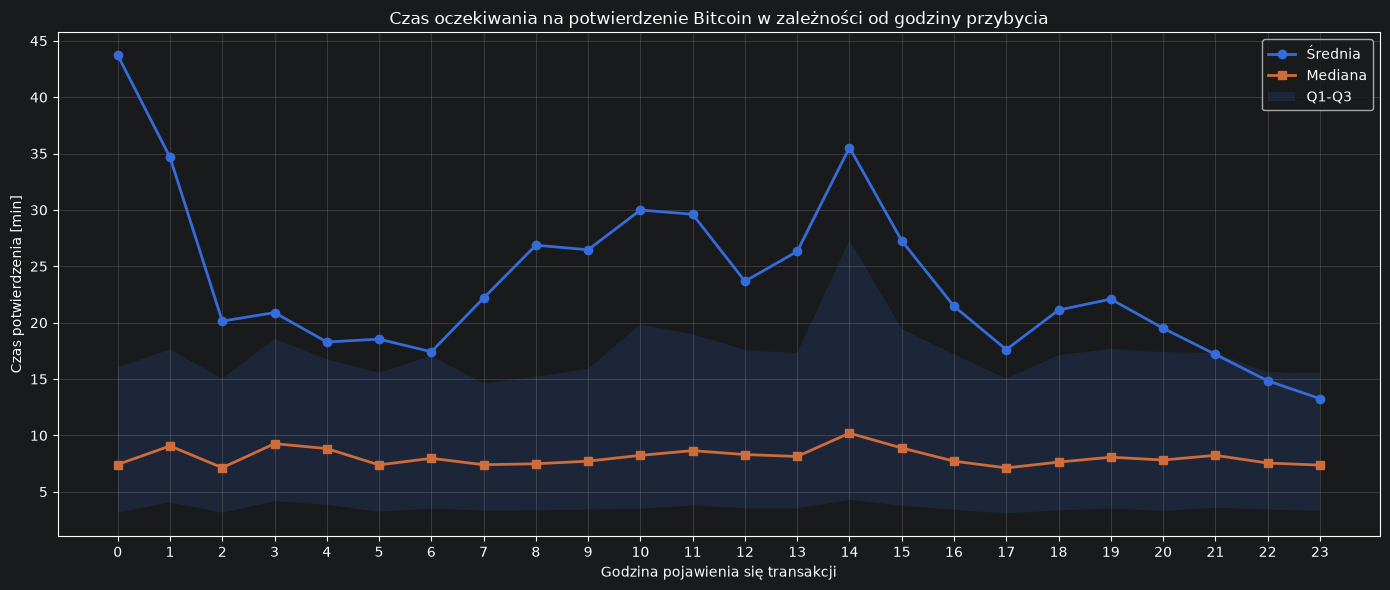

In [5]:

fig, ax = plt.subplots(figsize=(14, 6))

h = np.arange(24)

ax.plot(
    h,
    statystyki["srednia"],
    marker="o",
    linewidth=2,
    label="Średnia"
)

ax.plot(
    h,
    statystyki["mediana"],
    marker="s",
    linewidth=2,
    label="Mediana"
)

ax.fill_between(
    h,
    statystyki["Q1"].to_numpy(),
    statystyki["Q3"].to_numpy(),
    alpha=0.15,
    label="Q1-Q3"
)

ax.set_xlabel("Godzina pojawienia się transakcji")
ax.set_ylabel("Czas potwierdzenia [min]")
ax.set_title(
    "Czas oczekiwania na potwierdzenie Bitcoin "
    "w zależności od godziny przybycia"
)

ax.set_xticks(range(24))
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


### Boxploty

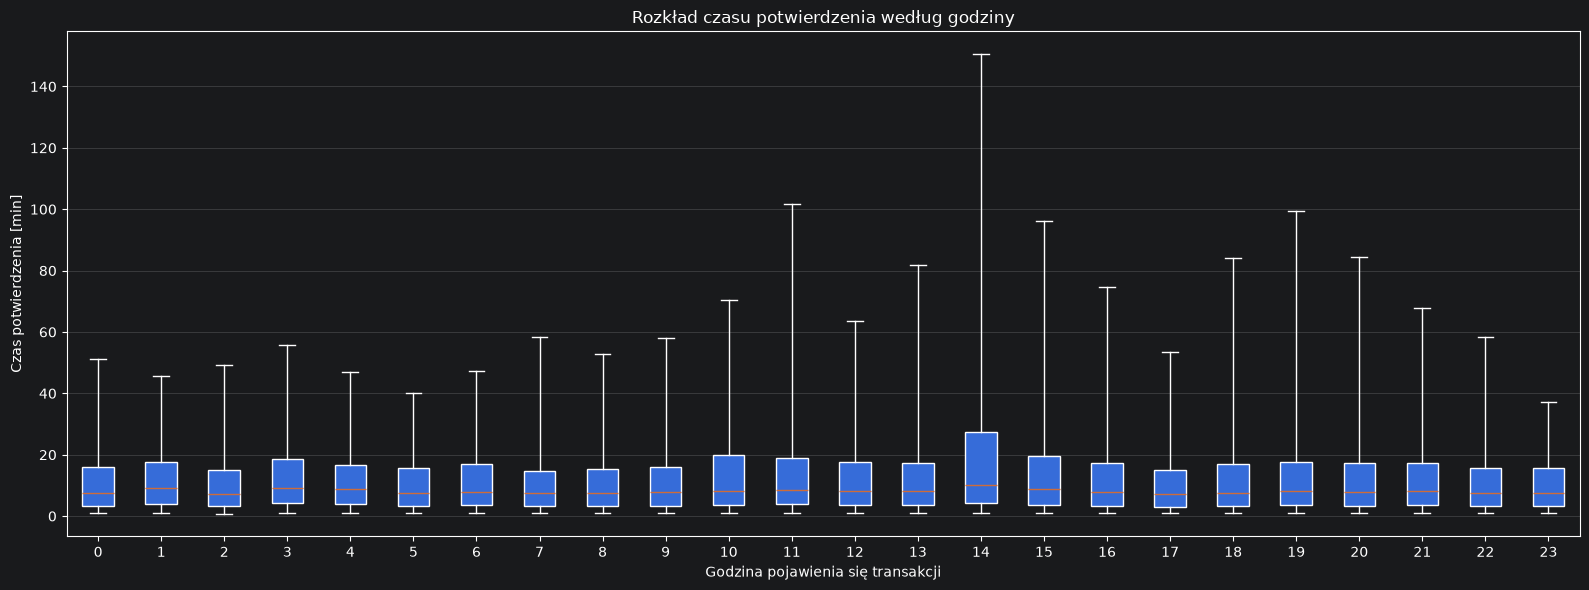

In [6]:

box_stats = []

for h in range(24):
    row = statystyki.loc[h]

    if pd.isna(row["mediana"]):
        continue

    box_stats.append({
        "label": str(h),
        "med": row["mediana"],
        "q1": row["Q1"],
        "q3": row["Q3"],
        "whislo": row["P05"],
        "whishi": row["P95"],
        "fliers": []
    })

fig, ax = plt.subplots(figsize=(16, 6))

ax.bxp(
    box_stats,
    showfliers=False,
    patch_artist=True
)

ax.set_xlabel("Godzina pojawienia się transakcji")
ax.set_ylabel("Czas potwierdzenia [min]")
ax.set_title("Rozkład czasu potwierdzenia według godziny")

ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Porównanie wariancji i IQR

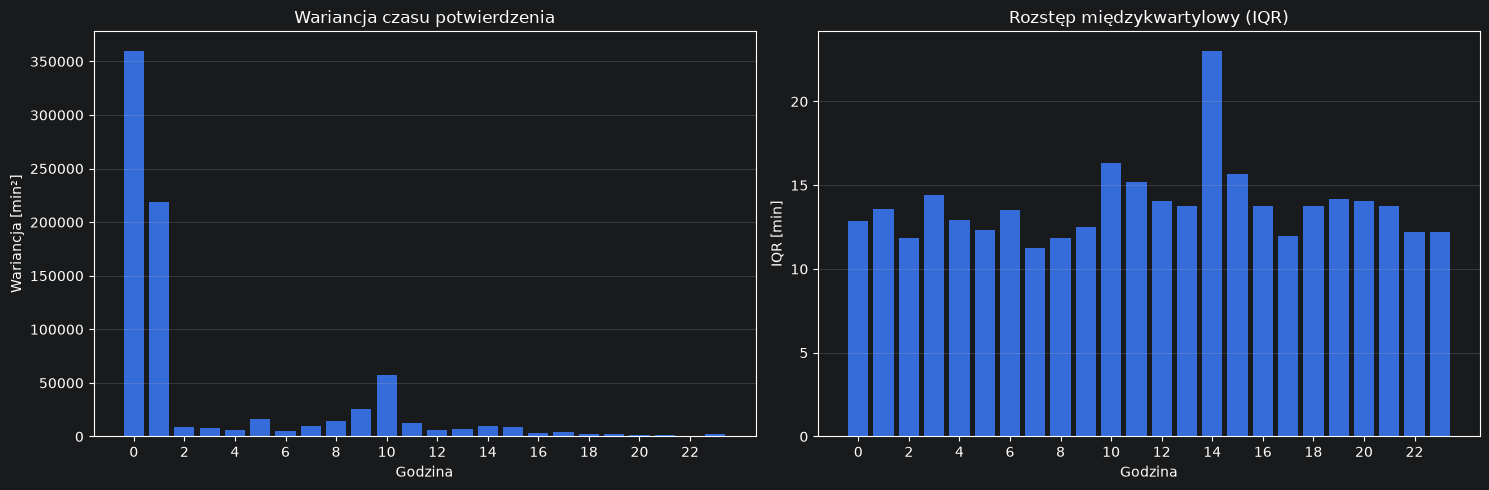

In [7]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(
    statystyki.index,
    statystyki["wariancja"]
)

axes[0].set_title("Wariancja czasu potwierdzenia")
axes[0].set_xlabel("Godzina")
axes[0].set_ylabel("Wariancja [min²]")
axes[0].set_xticks(range(0, 24, 2))
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    statystyki.index,
    statystyki["IQR"]
)

axes[1].set_title("Rozstęp międzykwartylowy (IQR)")
axes[1].set_xlabel("Godzina")
axes[1].set_ylabel("IQR [min]")
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


### Przedziały ufności

In [9]:

dzienne_godzinowe = (
    df.groupby(["dzien", "godzina"])["t_min"]
    .agg(n="size", suma="sum")
    .reset_index()
)

dni = dzienne_godzinowe["dzien"].unique()

liczby = (
    dzienne_godzinowe
    .pivot(index="dzien", columns="godzina", values="n")
    .reindex(index=dni, columns=range(24))
    .fillna(0)
    .to_numpy()
)

sumy = (
    dzienne_godzinowe
    .pivot(index="dzien", columns="godzina", values="suma")
    .reindex(index=dni, columns=range(24))
    .fillna(0)
    .to_numpy()
)

rng = np.random.default_rng(42)
B = 1000
bootstrap = np.full((B, 24), np.nan)

for b in range(B):
    idx = rng.integers(0, len(dni), len(dni))

    n = liczby[idx].sum(axis=0)
    suma = sumy[idx].sum(axis=0)

    bootstrap[b] = np.divide(
        suma, n,
        out=np.full(24, np.nan),
        where=n > 0
    )

ci_low, ci_high = np.nanpercentile(
    bootstrap,
    [2.5, 97.5],
    axis=0
)

statystyki["CI_low"] = ci_low
statystyki["CI_high"] = ci_high

display(
    statystyki[
        ["srednia", "CI_low", "CI_high"]
    ].round(3)
)


,srednia,CI_low,CI_high
godzina,,,
0,43.717,12.686,104.707
1,34.674,14.163,72.631
2,20.138,12.766,33.000
3,20.890,14.442,29.498
4,18.284,13.780,24.154
5,18.537,12.691,26.017
6,17.418,13.735,21.554
7,22.183,12.919,38.370
8,26.873,12.833,45.685


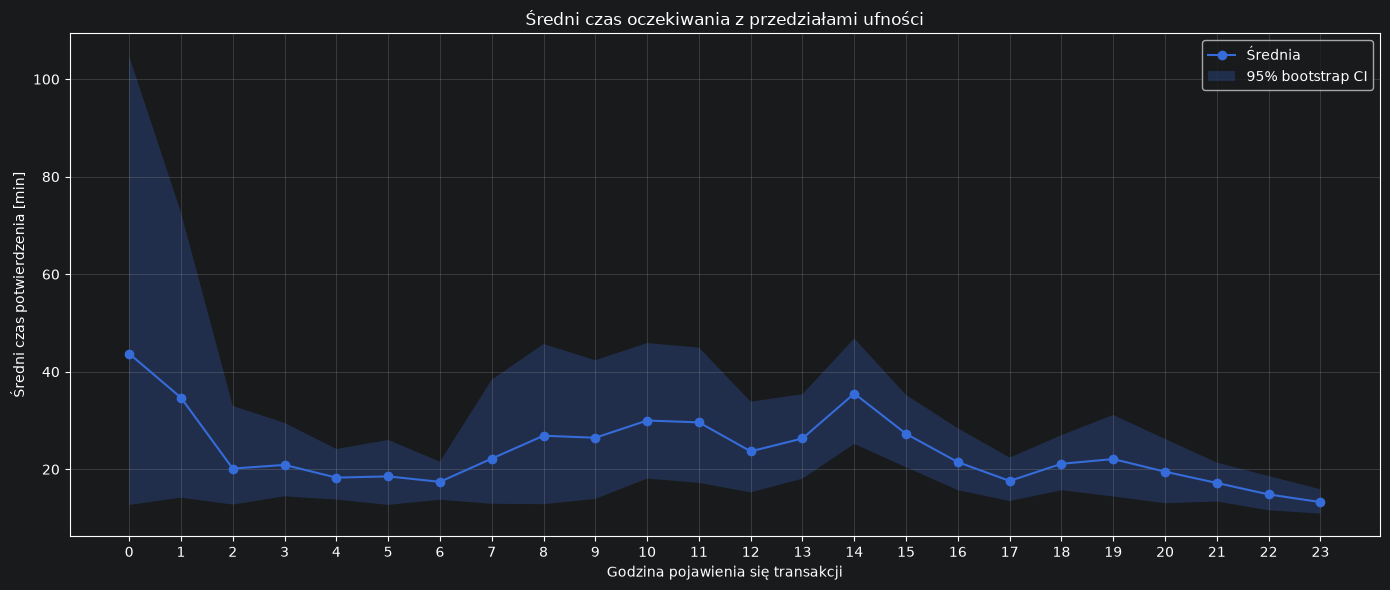

In [10]:

plt.figure(figsize=(14, 6))

plt.plot(
    range(24),
    statystyki["srednia"],
    marker="o",
    label="Średnia"
)

plt.fill_between(
    range(24),
    statystyki["CI_low"].to_numpy(),
    statystyki["CI_high"].to_numpy(),
    alpha=0.25,
    label="95% bootstrap CI"
)

plt.xlabel("Godzina pojawienia się transakcji")
plt.ylabel("Średni czas potwierdzenia [min]")
plt.title("Średni czas oczekiwania z przedziałami ufności")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
